1. random Walks

Lets start be plotting a singular singular simple random walk.

In [2]:
import matplotlib.pyplot as plt
from src.random_walk import random_walk, simulate_random_walks

Text(0, 0.5, 'Position')

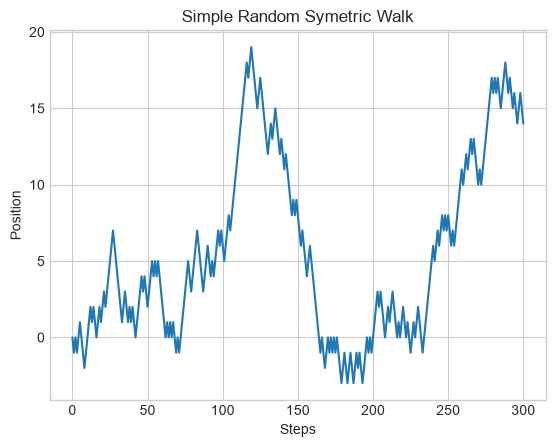

In [3]:
path = random_walk(0,300,0.5)

plt.plot(path)
plt.title("Simple Random Symetric Walk")
plt.xlabel("Steps")
plt.ylabel("Position")

Now lets simulate 20 paths with p = 0.6

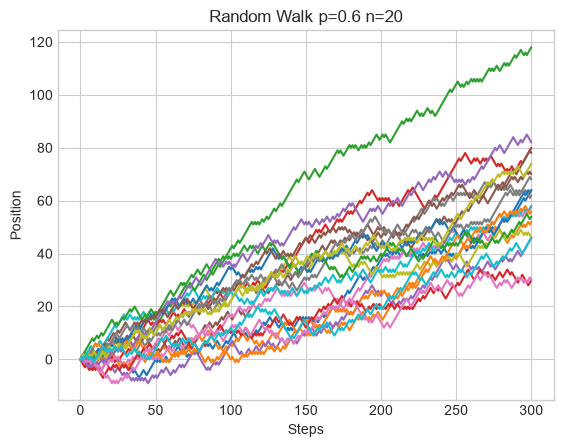

In [34]:
paths, final_positions = simulate_random_walks(20,0,300,0.6)
for i in paths:
    plt.plot(i)

plt.title("Random Walk p=0.6 n=20")
plt.xlabel("Steps")
plt.ylabel("Position")
plt.show()

We can verify the theoretical expectation E(Xn) = X0 + n*(p-q), in our case 60 and varience 4npq of 288.

In [3]:
import numpy as np

mean: 61.8
var: 370.76000000000005


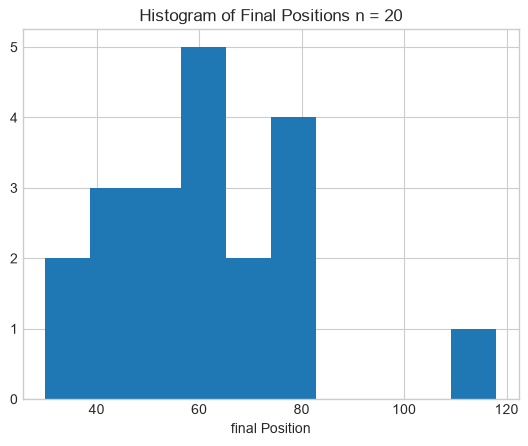

In [35]:
plt.hist(final_positions)
plt.title("Histogram of Final Positions n = 20")
plt.xlabel("final Position")

print("mean:", np.mean(final_positions))
print("var:", np.var(final_positions))

Now lets observe how the empircal expectation and varience behave as n increases.

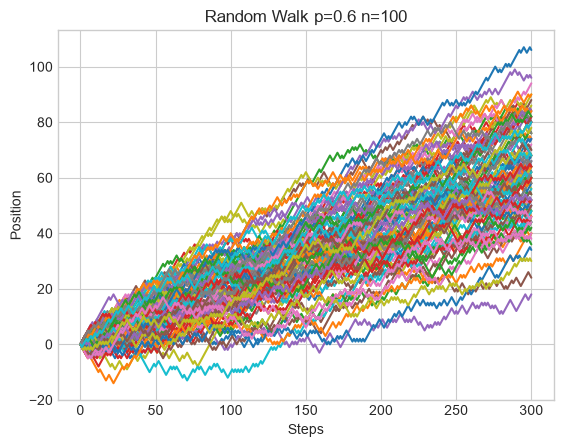

mean: 62.38
var: 271.6556


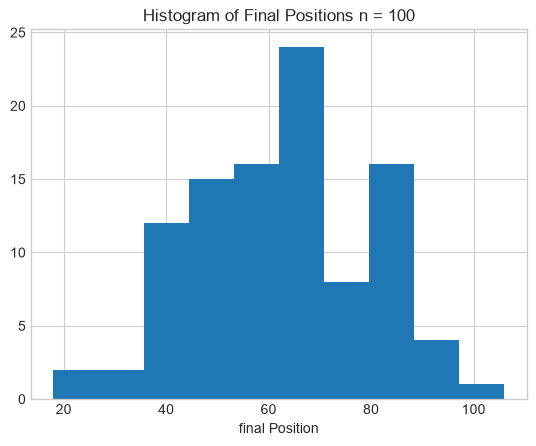

In [36]:
paths, final_positions = simulate_random_walks(100,0,300,0.6)

for i in paths:
    plt.plot(i)

plt.title("Random Walk p=0.6 n=100")
plt.xlabel("Steps")
plt.ylabel("Position")
plt.show()

plt.hist(final_positions)
plt.title("Histogram of Final Positions n = 100")
plt.xlabel("final Position")

print("mean:", np.mean(final_positions))
print("var:", np.var(final_positions))

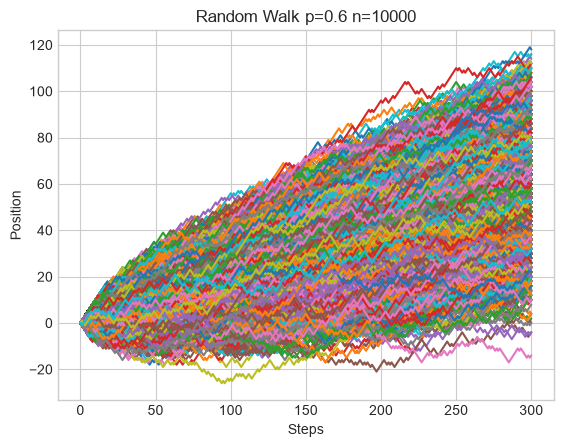

mean: 59.7074
var: 287.45558524


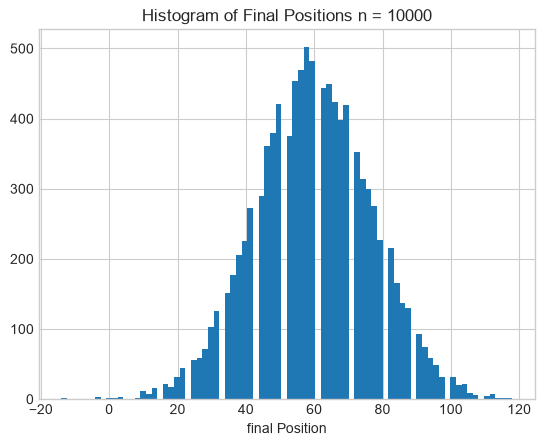

In [38]:
paths, final_positions = simulate_random_walks(10000,0,300,0.6)

for i in paths:
    plt.plot(i)

plt.title("Random Walk p=0.6 n=10000")
plt.xlabel("Steps")
plt.ylabel("Position")
plt.show()

plt.hist(final_positions, bins=80)
plt.title("Histogram of Final Positions n = 10000")
plt.xlabel("final Position")

print("mean:", np.mean(final_positions))
print("var:", np.var(final_positions))

2. Gamblers ruin

In [33]:
%load_ext autoreload
%autoreload 2
from src.gamblers_ruin import gamblers_ruin, simulate_gamblers_ruin, run_for_n, exact_duration_pmf


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Lets start by simulating a singular path starting at 20 with p = 0.5 and a barrier at 40

576 0


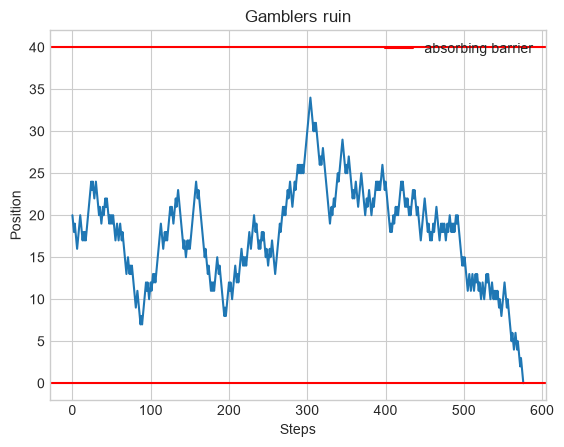

In [6]:
path, final_position, steps = gamblers_ruin(20,0.5,40)

plt.plot(path)
plt.title("Gamblers ruin")
plt.xlabel("Steps")
plt.ylabel("Position")
plt.axhline(y=40, color = "red", label = "absorbing barrier")
plt.axhline(y=0, color = "red")
plt.legend()

print(steps, final_position)

We can estimate the expected probability of ruin by simulation multiple paths and seeing the proportion of wins against losses. We can similarly estimate the duration of the game.

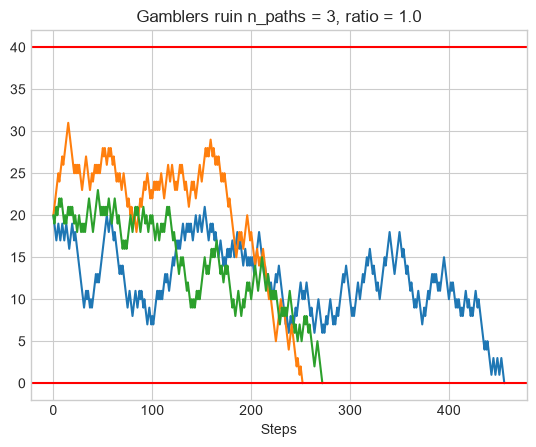

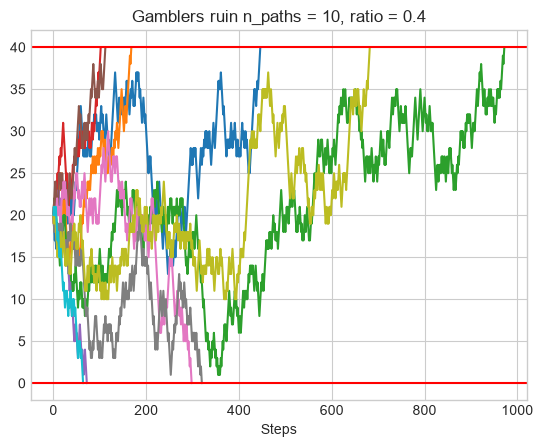

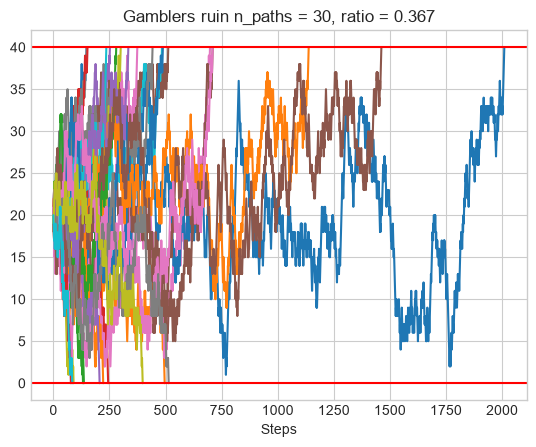

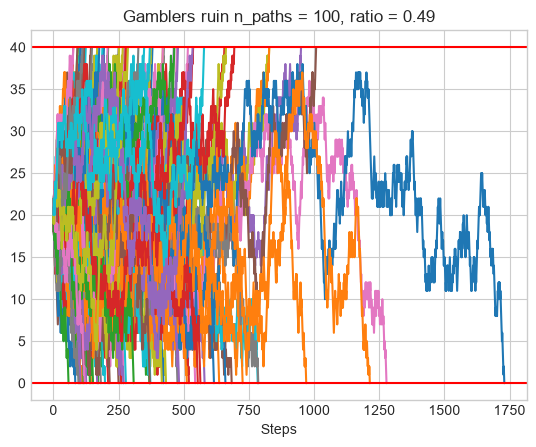

In [32]:
n_paths = [3,10,30, 100]
m = 40
for i in n_paths:
    paths, final_positions, steps = simulate_gamblers_ruin(i, 20,0.5, m)
    ratio = np.sum(np.array(final_positions) == 0)/i

    for j in paths:
        plt.plot(j)
    plt.title(f"Gamblers ruin n_paths = {i}, ratio = {round(ratio,3)}")
    plt.xlabel("Steps")
    plt.axhline(y=40, color = "red", label = "absorbing barrier")
    plt.axhline(y=0, color = "red")
    plt.show()




lets change m, p and starting positions

ratio: 0.36332


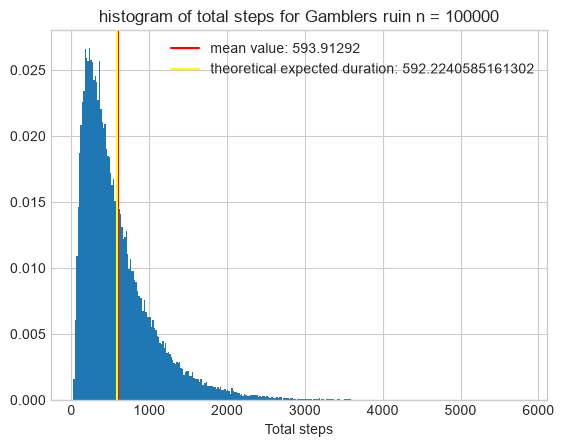

In [41]:
n_paths = 100000
m = 50
p = 0.51
a = 20
paths, final_positions, steps = simulate_gamblers_ruin(n_paths, a,p, m)

rho = (1-p)/p
expected_duration = (1/(1-2*p))*(a-m*((1-rho**a)/(1-rho**m)))

mean_duration = np.mean(steps)
median_duration = np.median(steps)

plt.hist(steps, bins=320, weights=np.ones_like(steps) / len(steps))
plt.title("histogram of total steps for Gamblers ruin n = 100000")
plt.axvline(x = mean_duration, color = "red", label = f"mean value: {mean_duration}")
plt.axvline(x = expected_duration, color = "yellow", label = f"theoretical expected duration: {expected_duration}")
plt.legend()
plt.xlabel("Total steps")

ratio = np.sum(np.array(final_positions) == 0)/n_paths
print("ratio:", ratio)

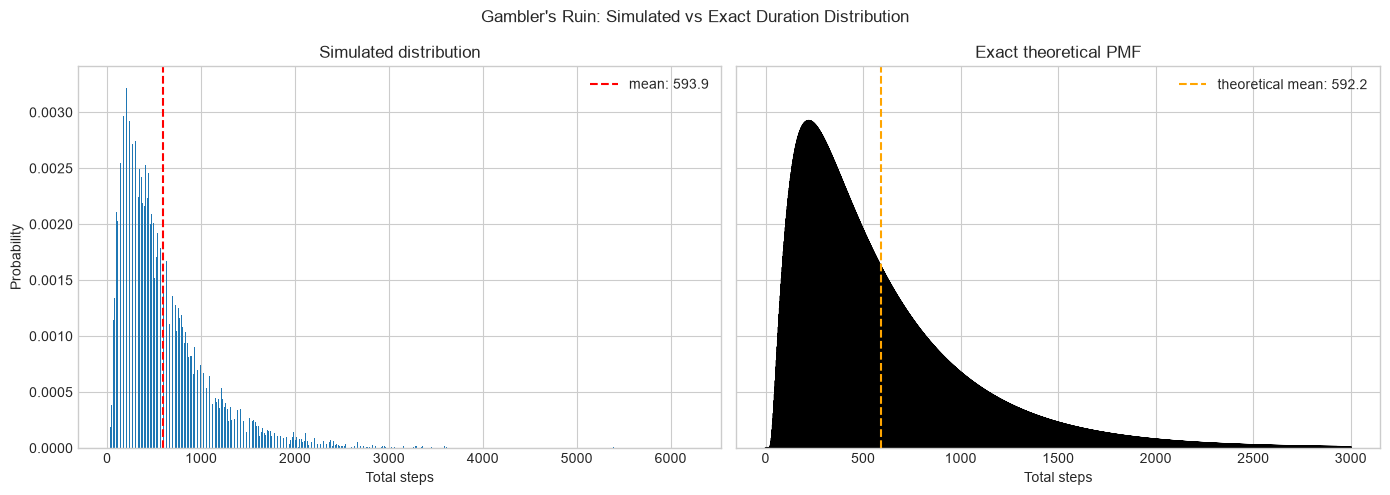

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

bins = np.arange(1, max_step + 2) - 0.5

# Left: simulated
axes[0].hist(steps, bins=bins, weights=np.ones_like(steps)/len(steps), color="tab:blue")
axes[0].axvline(mean_duration, color="red", linestyle="--", label=f"mean: {mean_duration:.1f}")
axes[0].set_title("Simulated distribution")
axes[0].set_xlabel("Total steps")
axes[0].set_ylabel("Probability")
axes[0].legend()

# Right: exact pmf
axes[1].plot(np.arange(1, len(pmf)+1), pmf, color="black")
axes[1].axvline(expected_duration, color="orange", linestyle="--", label=f"theoretical mean: {expected_duration:.1f}")
axes[1].set_title("Exact theoretical PMF")
axes[1].set_xlabel("Total steps")
axes[1].legend()

plt.suptitle("Gambler's Ruin: Simulated vs Exact Duration Distribution")
plt.tight_layout()
plt.show()

investigating how probability of ruin changes with start position and probability p

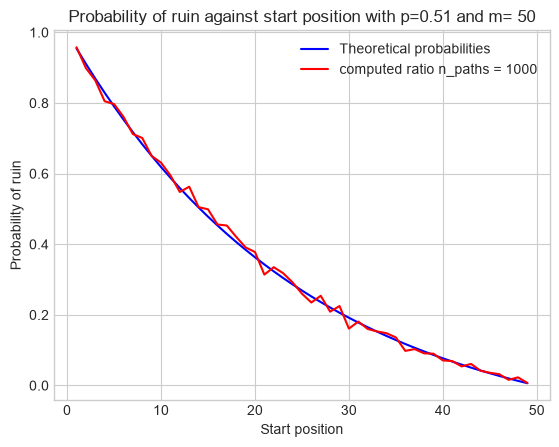

In [117]:
n_paths = 1000

m = 50
x = np.arange(1, 50)
ratios = []
p = 0.51
rho = (1-p)/p
theoretical_prob = (rho**x - rho**m)/(1-rho**m)
for i in x:
    final_positions = simulate_gamblers_ruin(n_paths, i,p, m)[1]
    ratio = np.sum(np.array(final_positions) == 0)/n_paths
    ratios.append(ratio)
plt.plot(x, theoretical_prob, label="Theoretical probabilities", color="blue")
plt.plot(x, ratios, label="computed ratio n_paths = 1000", color="red")
plt.legend()
plt.xlabel("Start position")
plt.ylabel("Probability of ruin")
plt.title("Probability of ruin against start position with p=0.51 and m= 50")
plt.show()

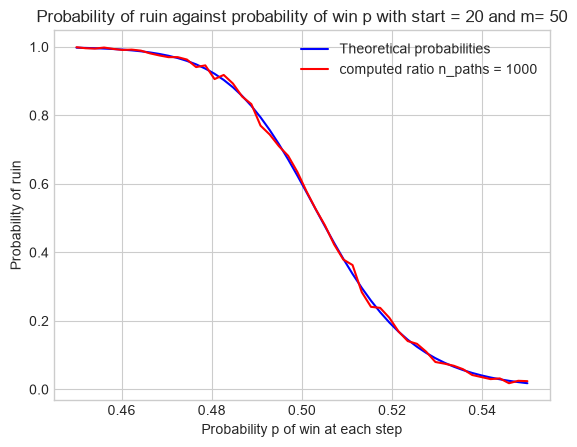

In [116]:
n_paths = 1000

m = 50
p = np.linspace(0.45, 0.55, 50)
ratios = []
rho = (1-p)/p
theoretical_prob = (rho**20 - rho**m)/(1-rho**m)
for i in p:
    final_positions = simulate_gamblers_ruin(n_paths, 20,i, m)[1]
    ratio = np.sum(np.array(final_positions) == 0)/n_paths
    ratios.append(ratio)
plt.plot(p, theoretical_prob, label="Theoretical probabilities", color="blue")
plt.plot(p, ratios, label="computed ratio n_paths = 1000", color="red")
plt.legend()
plt.xlabel("Probability p of win at each step")
plt.ylabel("Probability of ruin")
plt.title("Probability of ruin against probability of win p with start = 20 and m= 50")
plt.show()

In [18]:
from concurrent.futures import ProcessPoolExecutor

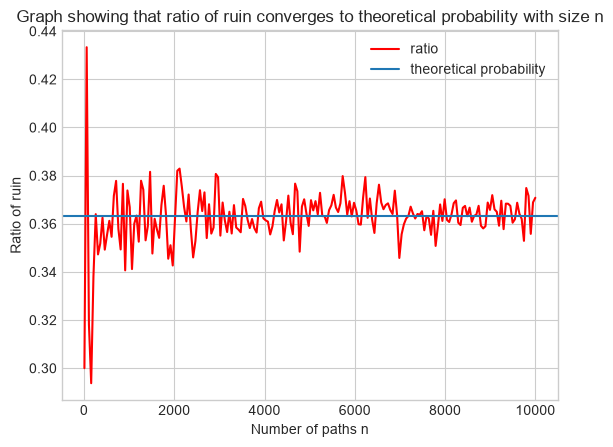

Text(0.5, 1.0, 'Associated error')

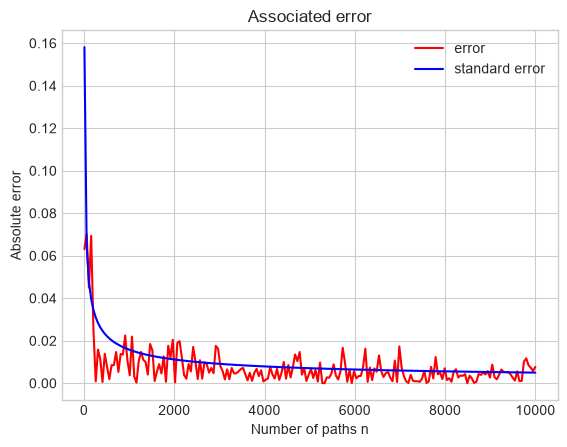

In [24]:
n_paths = np.linspace(10,10000,200).astype(int)

m = 50
p = 0.51
ratios = []
rho = (1-p)/p
theoretical_prob = (rho**20 - rho**m)/(1-rho**m)

args = [(n, 20, p, m) for n in n_paths]

with ProcessPoolExecutor() as executor:
    ratios = list(executor.map(run_for_n, args))

error = abs(np.array(ratios) - theoretical_prob)
standard_error = ((p*(1-p))/n_paths)**0.5
plt.plot(n_paths, ratios, label="ratio", color="red")
plt.axhline(y=theoretical_prob, label= "theoretical probability")
plt.legend()
plt.xlabel("Number of paths n")
plt.ylabel("Ratio of ruin")
plt.title("Graph showing that ratio of ruin converges to theoretical probability with size n")
plt.show()

plt.plot(n_paths, error, label="error", color="red")
plt.plot(n_paths, standard_error, label="standard error", color="blue")
plt.legend()
plt.xlabel("Number of paths n")
plt.ylabel("Absolute error")
plt.title("Associated error")